# Actividad Semana 8 - Segmentación de clientes con K-Means

## Objetivo

En esta actividad voy a aplicar K-Means para identificar distintos grupos de clientes según sus hábitos de compra y su comportamiento dentro del sitio.

La idea es trabajar sin etiquetas previas y ver si aparecen segmentos con características similares, por ejemplo clientes que compran seguido, clientes que gastan más por compra o clientes más sensibles a los descuentos.

Para eso voy a probar distintos valores de K entre 2 y 6 y comparar los resultados usando el método del codo. Después voy a analizar los centroides para interpretar qué representa cada grupo de clientes.

## 1. Carga y revisión inicial de los datos

In [16]:
import pandas as pd

df = pd.read_csv("dataset_segmentacion_clientes.csv")

df.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


In [17]:
df.shape

(700, 7)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   purchase_freq_month   700 non-null    float64
 1   avg_basket_usd        700 non-null    float64
 2   time_on_site_min      700 non-null    float64
 3   discount_sensitivity  700 non-null    float64
 4   returns_rate          700 non-null    float64
 5   noise_gauss           700 non-null    float64
 6   noise_uniform         700 non-null    float64
dtypes: float64(7)
memory usage: 38.4 KB


## 2. Preparación de los datos

El dataset incluye dos columnas de ruido que no forman parte de las variables indicadas en la consigna. Por eso, voy a eliminarlas antes de aplicar K-Means y trabajar solamente con las cinco variables relacionadas con el comportamiento de los clientes.

In [19]:
df = df.drop(columns=["noise_gauss", "noise_uniform"])

df.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,11.152508,181.300834,33.564036,1.000000,0.800000
1,12.053451,178.637272,35.432081,0.784974,0.000000
2,2.203006,450.185298,7.030757,0.898297,0.000000
3,4.233314,89.006342,10.834453,0.000000,0.800000
4,1.716799,449.773982,7.254548,0.000000,0.003279


In [20]:
df.shape

(700, 5)

## 3. Revisión de las escalas

Antes de aplicar K-Means voy a revisar los valores de cada variable. Como el algoritmo trabaja con distancias, es importante que ninguna variable tenga más peso solo por estar medida en una escala más grande.

In [21]:
df.describe()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
count,700.000000,700.000000,700.000000,700.000000,700.000000
mean,5.875724,248.173491,16.784799,0.425083,0.337194
std,4.471079,154.904372,12.914111,0.431467,0.356623
min,0.100000,86.994100,3.163206,0.000000,0.000000
25%,2.278418,90.766945,6.603950,0.000000,0.000000
50%,4.134580,180.223799,9.974407,0.296475,0.165559
75%,11.214919,449.719033,34.341360,1.000000,0.800000
max,14.603388,452.973583,38.348156,1.000000,0.800000


## 4. Estandarización de las variables

Como las variables están medidas en escalas distintas y K-Means trabaja con distancias, voy a estandarizarlas antes de entrenar los modelos. De esta forma, ninguna variable va a tener más peso solamente por manejar valores más grandes.

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

print("Media:", X_scaled.mean(axis=0))
print("Desviación estándar:", X_scaled.std(axis=0))

X_scaled[:5]

Media: [-1.25613805e-16 -1.77635684e-17  1.58603289e-16  7.61295788e-17
 -1.90323947e-17]
Desviación estándar: [1. 1. 1. 1. 1.]


array([[ 1.18104766, -0.43201153,  1.3002238 ,  1.33342344,  1.29867122],
       [ 1.38269638, -0.4492187 ,  1.44497872,  0.83470573, -0.9461957 ],
       [-0.82202607,  1.30503906, -0.75584112,  1.09754027, -0.9461957 ],
       [-0.36760354, -1.02825349, -0.46109255, -0.98590965,  1.29867122],
       [-0.93084879,  1.30238187, -0.73849955, -0.98590965, -0.93699568]])

## 5. Prueba de distintos valores de K

Como no sabemos de antemano cuántos grupos de clientes existen, voy a probar distintos valores de K entre 2 y 6.

Para comparar los modelos voy a guardar la inercia de cada uno y después analizar los resultados con el método del codo.

In [34]:
from sklearn.cluster import KMeans

inercias = []

for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    modelo.fit(X_scaled)
    inercias.append(modelo.inertia_)

inercias

[2088.881212909858,
 1408.7024362226662,
 1173.438207194585,
 997.7424877262393,
 762.4660975829854]

## 6. Método del codo

Ahora voy a graficar la inercia para cada valor de K. La idea es buscar el punto donde la mejora empieza a ser cada vez menor, ya que eso puede ayudar a elegir una cantidad razonable de clusters.

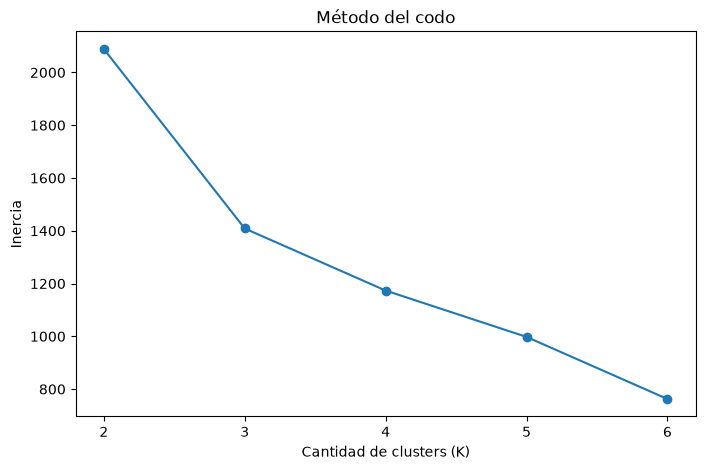

In [37]:
import matplotlib.pyplot as plt

valores_k = range(2, 7)

plt.figure(figsize=(8, 5))
plt.plot(valores_k, inercias, marker="o")
plt.xlabel("Cantidad de clusters (K)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(valores_k)
plt.show()

### Interpretación

En el gráfico se nota una disminución importante de la inercia entre K=2 y K=3. A partir de K=3 sigue bajando, pero de una forma más gradual.

Por eso, K=3 parece ser una cantidad razonable de clusters. De todas formas, antes de elegir el valor final voy a compararlo con el índice Silhouette.

## 7. Índice Silhouette

Además de la inercia, voy a calcular el índice Silhouette para comparar qué tan bien separados quedan los clusters con cada valor de K.

Un valor más alto de Silhouette indica que los grupos están mejor diferenciados entre sí.

In [35]:
from sklearn.metrics import silhouette_score

silhouettes = []

for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, etiquetas)
    silhouettes.append(score)

silhouettes

[0.3997478892553071,
 0.4305114235798075,
 0.42945024454282255,
 0.41982392945745495,
 0.4610493091071315]

### Comparación del índice Silhouette

Para comparar mejor los resultados, voy a graficar el valor de Silhouette obtenido para cada cantidad de clusters.

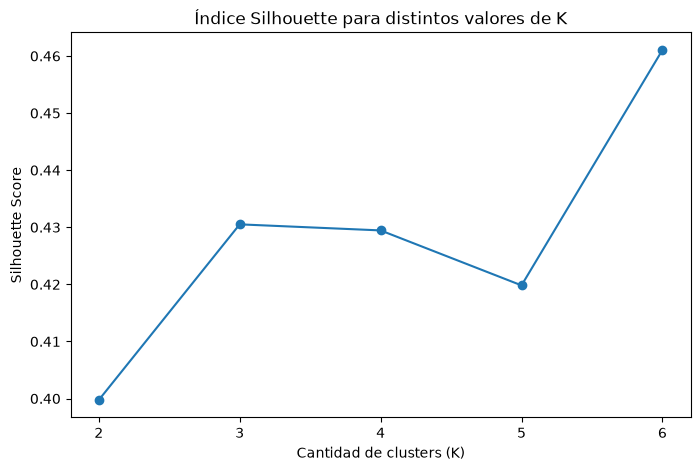

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(valores_k, silhouettes, marker="o")
plt.xlabel("Cantidad de clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Índice Silhouette para distintos valores de K")
plt.xticks(valores_k)
plt.show()

### Interpretación del índice Silhouette

El método del codo muestra que K=3 es una opción razonable porque, a partir de ese punto, la reducción de la inercia empieza a ser más gradual.

Por otro lado, el índice Silhouette obtiene su valor más alto con K=6, lo que muestra que con seis clusters los grupos quedan mejor separados.

Como en esta actividad buscamos encontrar distintos perfiles de clientes, voy a usar K=6 para el modelo final. Después voy a revisar los centroides para comprobar si esos seis grupos también muestran diferencias claras en el comportamiento de los clientes.

## 8. Modelo final con K=6

Con los resultados anteriores, voy a entrenar el modelo final de K-Means usando 6 clusters.

Después voy a agregar al dataset el cluster que le corresponde a cada cliente para poder analizar mejor cada grupo.

In [38]:
modelo_final = KMeans(
    n_clusters=6,
    init="k-means++",
    random_state=42,
    n_init=10
)

clusters = modelo_final.fit_predict(X_scaled)

df["cluster"] = clusters

df.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,cluster
0,11.152508,181.300834,33.564036,1.000000,0.800000,4
1,12.053451,178.637272,35.432081,0.784974,0.000000,4
2,2.203006,450.185298,7.030757,0.898297,0.000000,2
3,4.233314,89.006342,10.834453,0.000000,0.800000,5
4,1.716799,449.773982,7.254548,0.000000,0.003279,2


## 9. Análisis de los clusters

Ahora voy a analizar los centroides de cada cluster.

Como el modelo se entrenó con los datos estandarizados, voy a volver a llevar los centroides a la escala original. Así los valores se pueden interpretar más fácilmente y comparar las características de cada grupo de clientes.

In [39]:
centroides = scaler.inverse_transform(modelo_final.cluster_centers_)

centroides_df = pd.DataFrame(
    centroides,
    columns=[
        "Frecuencia de compra",
        "Ticket promedio",
        "Tiempo en el sitio",
        "Sensibilidad a descuentos",
        "Tasa de devoluciones"
    ]
)

centroides_df.index.name = "Cluster"

centroides_df

,Frecuencia de compra,Ticket promedio,Tiempo en el sitio,Sensibilidad a descuentos,Tasa de devoluciones
Cluster,,,,,
0,4.009556,90.008042,9.973569,0.399260,0.031112
1,11.952603,179.993999,35.130414,0.112836,0.353236
2,1.879360,450.194607,5.874735,0.361110,0.037886
3,1.812861,450.049399,6.077611,0.354917,0.729453
4,11.968991,180.004187,34.922872,0.934516,0.313418
5,4.225175,89.875846,10.052726,0.347417,0.732097


### Interpretación de los clusters

Mirando los centroides de cada cluster se pueden distinguir distintos tipos de clientes:

- **Cluster 0:** clientes que compran con una frecuencia media-baja, gastan poco por compra, pasan poco tiempo en el sitio y casi no hacen devoluciones.

- **Cluster 1:** clientes que compran seguido, tienen un ticket medio, pasan bastante tiempo en el sitio y no parecen depender demasiado de los descuentos.

- **Cluster 2:** clientes que compran pocas veces, pero cuando lo hacen gastan bastante. También pasan poco tiempo en el sitio y tienen pocas devoluciones.

- **Cluster 3:** tiene un comportamiento parecido al Cluster 2 porque también compra poco y tiene un ticket alto, pero se diferencia porque presenta una tasa de devoluciones mucho mayor.

- **Cluster 4:** clientes que compran seguido, tienen un ticket medio y pasan bastante tiempo en el sitio. A diferencia del Cluster 1, este grupo muestra una sensibilidad muy alta a los descuentos.

- **Cluster 5:** clientes que compran con una frecuencia media-baja y tienen un ticket bajo, pero presentan una tasa de devoluciones alta.

## 10. Recomendaciones

A partir de los grupos encontrados, se pueden pensar distintas acciones según el comportamiento de cada tipo de cliente.

Por ejemplo, los clientes más sensibles a los descuentos podrían responder mejor a promociones o beneficios específicos.

En cambio, con los clientes que compran pocas veces pero gastan bastante en cada compra se podrían buscar formas de aumentar la frecuencia con la que vuelven a comprar.

También estaría bueno revisar con más detalle los clusters que tienen muchas devoluciones para tratar de entender qué puede estar generando ese comportamiento.

En general, la segmentación permitió encontrar distintos perfiles de clientes con comportamientos bastante diferentes. Para el modelo final elegí K=6 porque fue el valor con mejor Silhouette entre los que probé y, al revisar los centroides, también se pudieron distinguir características claras entre los grupos.